# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn (including DecisionTreeClassifier, RandomForestClassifier and GradingBoostingClassifier)
- Matplotlib


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [2]:

df = pd.read_csv('adviseinvest_historical_data.csv')
display(df.head())
df.info()
display(df.describe(include='all'))
print("Missing Values:")
print(df.isnull().sum())
print("Duplicates", df.duplicated().sum())
print("Minimum")
print(df.select_dtypes(include='number').min())
print("Maximum")
print(df.select_dtypes(include='number').max())


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
unique,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,27903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,14850.475563,0.546638,33766.893303,NaN,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,NaN,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,NaN,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,NaN,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,NaN,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,NaN,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000


Missing Values:
customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64
Duplicates 3
Minimum
customer_id          99.0
answered              0.0
income           -65600.0
age                  19.0
job                   0.0
num_dependents        1.0
rent                  0.0
own_res               0.0
new_car               0.0
chk_acct              0.0
sav_acct              0.0
num_accts             0.0
mobile                0.0
product               0.0
dtype: float64
Maximum
customer_id        29602.0
answered               1.0
income            159450.0
age                  132.0
job                    3.0
num_dependents         2.0
rent                   1.0
own_res                1.0
new_car                1.0
chk_acct            

### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1.
The ones that I would say seem unusual are the missing values in new car and then also the negative income of 65,6 and finally the age of 132 is also unusual.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [3]:

df_clean = df.copy()
df_clean = df_clean.drop_duplicates()
df_clean = df_clean[
    (df_clean['income'] >= 0) &
    (df_clean['age'].between(18, 100))
].copy()
df_clean['new_car'] = df_clean['new_car'].fillna(
    df_clean['new_car'].mode()[0]
)
df_clean = df_clean.drop(columns=['customer_id', 'product'])
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Missing values:", df_clean.isnull().sum().sum())
display(df_clean.head())


Original rows: 29504
Cleaned rows: 29498
Missing values: 0


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,0,4330,0,24,2,2,1,0,0.0,1,3,1,0
2,0,4330,0,22,2,1,1,0,0.0,3,0,0,0
3,0,4330,0,24,2,2,1,0,0.0,1,3,1,0
4,0,4330,0,22,2,1,1,0,0.0,3,0,0,0
6,0,4330,0,22,2,1,1,0,0.0,3,0,0,0


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5
I first removed the duplicate rows and then got rid of the values that were unrealistic like the negative income and age over 110. Finally I filled the missing values in new car and just did it with the most common value because there were only two missing entries.
2.6
I removed customer id because it doesnt help with what we're doign for this assignment.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [4]:

df_clean['answered'] = df_clean['answered'].astype(bool)
int_columns = [
    'income', 'age', 'num_dependents',
    'num_accts', 'new_car'
]

for col in int_columns:
    df_clean[col] = df_clean[col].astype(int)
print(df_clean.dtypes)


answered            bool
income             int64
female            object
age                int64
job                int64
num_dependents     int64
rent               int64
own_res            int64
new_car            int64
chk_acct           int64
sav_acct           int64
num_accts          int64
mobile             int64
dtype: object


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [5]:

cat_columns = ['job', 'chk_acct', 'sav_acct']
for col in cat_columns:
    df_clean[col] = df_clean[col].astype('category')
print(df_clean.dtypes)


answered              bool
income               int64
female              object
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car              int64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



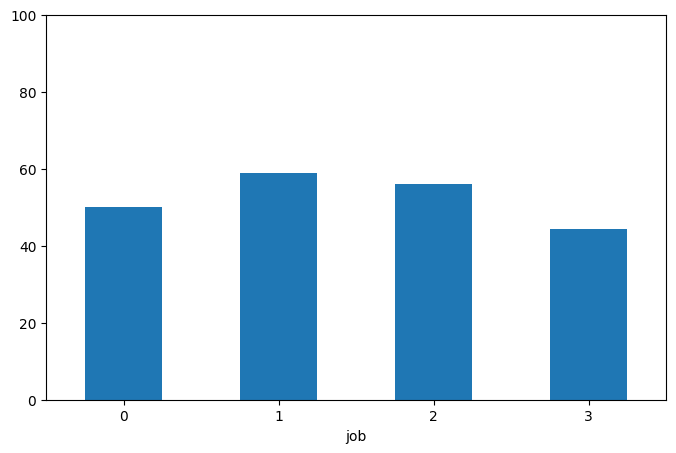

In [6]:

job_answer = df_clean.groupby('job', observed=True)['answered'].mean() * 100

plt.figure(figsize=(8, 5))
job_answer.plot(kind='bar')

plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()



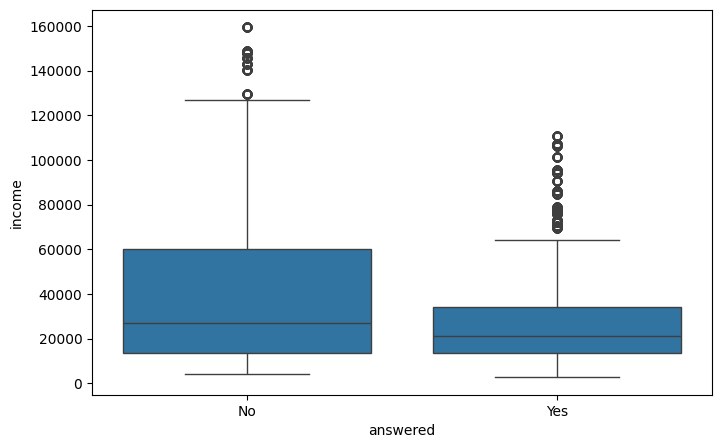

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='answered',
    y='income'
)

plt.xticks([0, 1], ['No', 'Yes'])
plt.show()

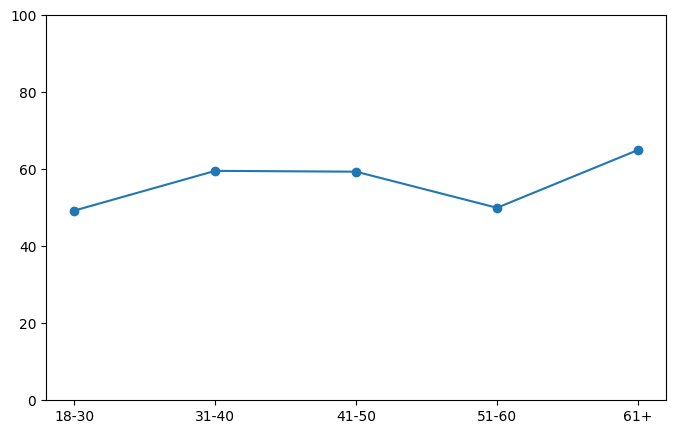

In [8]:

# Create age groups
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[18, 30, 40, 50, 60, 100],
    labels=['18-30', '31-40', '41-50', '51-60', '61+'],
    include_lowest=True
)

age_answer = df_clean.groupby(
    'age_group', observed=True
)['answered'].mean() * 100

plt.figure(figsize=(8, 5))
plt.plot(age_answer.index.astype(str),
         age_answer.values, marker='o')

plt.ylim(0, 100)
plt.show()


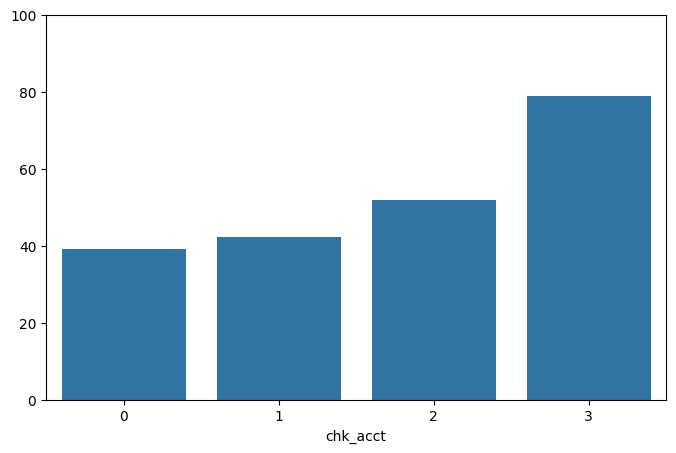

In [9]:

chk_answer = df_clean.groupby(
    'chk_acct', observed=True
)['answered'].mean() * 100

plt.figure(figsize=(8, 5))

sns.barplot(
    x=chk_answer.index.astype(str),
    y=chk_answer.values
)

plt.ylim(0, 100)
plt.show()


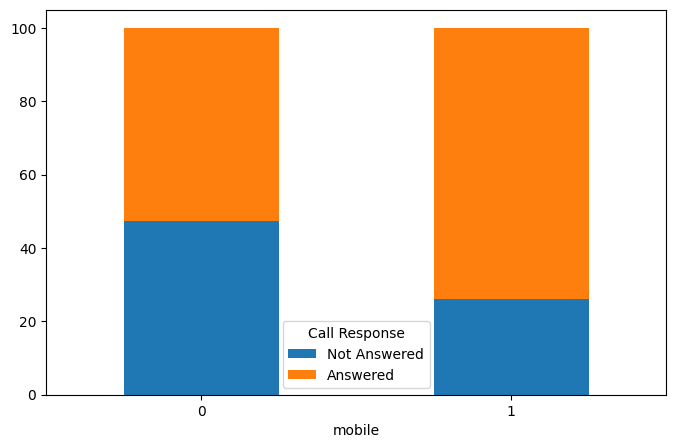

In [10]:

mobile_response = pd.crosstab(
    df_clean['mobile'],
    df_clean['answered'],
    normalize='index'
) * 100

mobile_response.columns = ['Not Answered', 'Answered']

mobile_response.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.xticks(rotation=0)
plt.legend(title='Call Response')
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. mobile phone status seems to have the strongest relationship with whether custeomers answer. Also Checking account status is up there.

3.7.   
Yes JOb type is one that had a weak relationship

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [11]:

base_probability = df_clean['answered'].mean()

print("Base Probability of Answering:", base_probability)
print("Answer Rate:", round(base_probability * 100, 2), "%")
baseline_accuracy = max(base_probability, 1 - base_probability)

print("Baseline Accuracy:", round(baseline_accuracy * 100, 2), "%")


Base Probability of Answering: 0.5467150315275612
Answer Rate: 54.67 %
Baseline Accuracy: 54.67 %


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [13]:

X = df_clean.drop(columns=['answered', 'age_group'], errors='ignore')
y = df_clean['answered'].astype(int)
X = pd.get_dummies(X, columns=['job', 'chk_acct', 'sav_acct'])
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Total features:", X.shape[1])


Training rows: 23598
Testing rows: 5900
Total features: 22


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

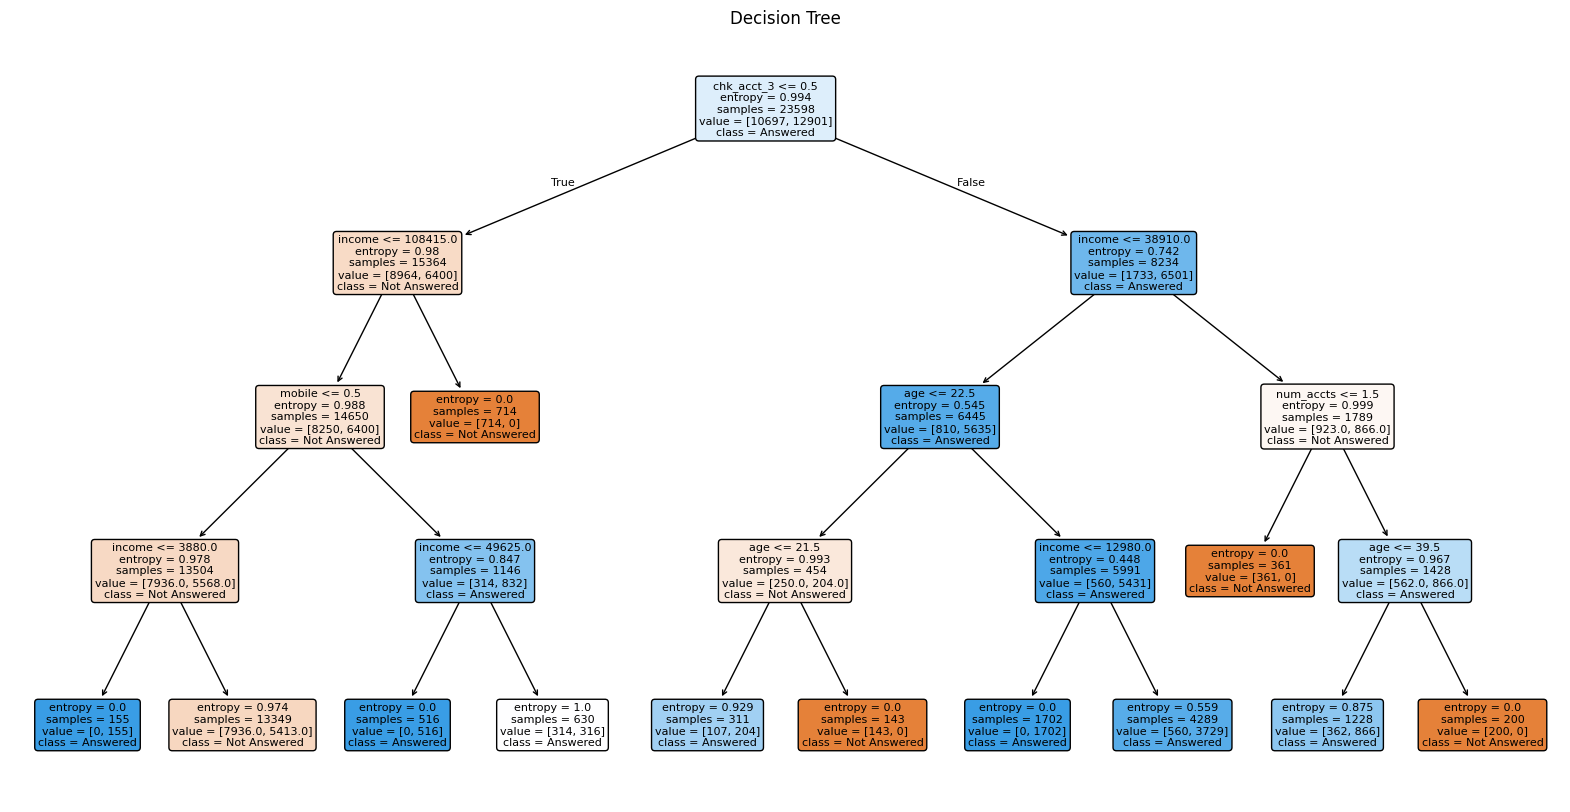

In [14]:

tree = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=4,
    random_state=42
)
tree.fit(X_train, y_train)
plt.figure(figsize=(20, 10))

plot_tree(
    tree,
    feature_names=X.columns,
    class_names=['Not Answered', 'Answered'],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree")
plt.show()


## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [16]:
tree_pred = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_pred)

print("Decision Tree Accuracy:", round(tree_accuracy * 100, 2), "%")
print("Baseline Accuracy:", round(baseline_accuracy * 100, 2), "%")

print("Improvement:", round(
    (tree_accuracy - baseline_accuracy) * 100, 2
), "percentage points")


ValueError: could not convert string to float: 'M'

### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1.

2.


## 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [18]:


X = pd.get_dummies(
    df_clean.drop(columns=['answered', 'age_group'], errors='ignore')
)

y = df_clean['answered'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
tree = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=4,
    random_state=42
)

tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
cm = confusion_matrix(y_test, tree_pred)

print("Confusion Matrix:")
print(cm)



Confusion Matrix:
[[2353  321]
 [1371 1855]]


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

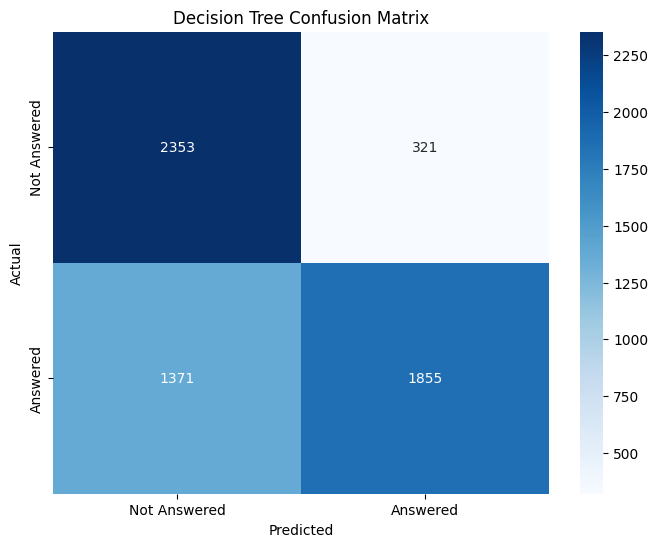

In [19]:

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Answered', 'Answered'],
    yticklabels=['Not Answered', 'Answered']
)

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


## 4.6 Check for Overfitting and Underfitting

A model may perform very well on its training data but poorly on new data. This is called **overfitting**. A model may also perform poorly on both training and test data. This is called **underfitting**.

Remember that we can evaluate fit with these guidelines:
- **Overfit:** Training accuracy is much higher than test accuracy.
- **Underfit:** Both training and test accuracy are low.
- **Balanced:** Training and test accuracy are fairly close, and test accuracy is meaningfully better than the baseline probability.


### Do the following:

- Calculate the accuracy of your decision tree on the training data.
- Compare it to the accuracy on the testing data.
- Calculate the difference between the two accuracy scores.

In [21]:

train_accuracy = accuracy_score(
    y_train, tree.predict(X_train)
)

test_accuracy = accuracy_score(
    y_test, tree.predict(X_test)
)
difference = train_accuracy - test_accuracy

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")
print("Difference:", round(difference * 100, 2), "percentage points")


Training Accuracy: 71.37 %
Testing Accuracy: 71.32 %
Difference: 0.05 percentage points


### Reflection:
1. Does your model appear to be overfit, underfit, or reasonably balanced? Explain using the training and testing accuracy scores.
2. If the model is overfit, what changes could you make to simplify it?
3. If the model is underfit, what changes could you make to allow it to identify more patterns?
### ✍️ Your Response: 🔧
1. My model appear to be reasonably balanced because the difference was almost 0
2. I could reduce the tree depth
3. I could increase the tree depth

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [22]:

tn, fp, fn, tp = confusion_matrix(y_test, tree_pred).ravel()
model_profit = (tp * 75) - (fp * 25)

print("True Positives:", tp)
print("False Positives:", fp)
print("Total Model Profit: $", model_profit)


True Positives: 1855
False Positives: 321
Total Model Profit: $ 131100


## 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [23]:

total_answered = (y_test == 1).sum()
total_not_answered = (y_test == 0).sum()
default_profit = (total_answered * 75) - (total_not_answered * 25)
profit_difference = model_profit - default_profit

print("Default Profit", default_profit)
print("Model ", model_profit)
print("Profit Difference:", profit_difference)


Default Profit 175100
Model  131100
Profit Difference: -44000


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Using the model generated 43950 less in profit

2. Yes that is a large percentage of profit lost


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [25]:

results = []

best_accuracy = 0
best_tree = None

for depth in [3, 4, 5, 6, 8, 10, 12]:
    for min_samples in [2, 5, 10, 20, 50]:

        tuned = DecisionTreeClassifier(
            criterion='entropy',
            max_depth=depth,
            min_samples_split=min_samples,
            random_state=42
        )

        tuned.fit(X_train, y_train)

        predictions = tuned.predict(X_test)
        accuracy = accuracy_score(y_test, predictions)

        results.append([depth, min_samples, accuracy])

        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_tree = tuned
tuning_results = pd.DataFrame(
    results,
    columns=['Max Depth', 'Min Samples Split', 'Accuracy']
)
display(tuning_results.sort_values(
    by='Accuracy', ascending=False
).head(10))
tree_accuracy = accuracy_score(y_test, tree.predict(X_test))
print("Original Accuracy:", round(tree_accuracy * 100, 2), "%")
print("Best Tuned Accuracy:", round(best_accuracy * 100, 2), "%")
print("Improvement:", round(
    (best_accuracy - tree_accuracy) * 100, 2
), "percentage points")
tuned_tree = best_tree
tuned_pred = tuned_tree.predict(X_test)


,Max Depth,Min Samples Split,Accuracy
32,12,10,0.836949
33,12,20,0.836949
34,12,50,0.836949
31,12,5,0.836949
30,12,2,0.836949
25,10,2,0.808136
27,10,10,0.808136
28,10,20,0.808136
26,10,5,0.808136
29,10,50,0.808136


Original Accuracy: 71.32 %
Best Tuned Accuracy: 83.69 %
Improvement: 12.37 percentage points


## 5.4 Create a Random Forest Model

A random forest combines the predictions of many decision trees. Each tree uses a different random sample of the training data and considers a random subset of variables at each split. Combining the trees can produce a more stable prediction than relying on one tree.

### Do the following:
- Import and create a RandomForestClassifier model.
- Use at least 100 trees (n_estimators=100) and set random_state=42.
- Fit the model using the same training data used for the decision tree.
- Predict whether customers in the test data will answer.
- Calculate the test accuracy and display a confusion matrix.
- Create a feature-importance chart for the random forest.

Random Forest Accuracy: 100.0 %
Confusion Matrix:
[[2674    0]
 [   0 3226]]


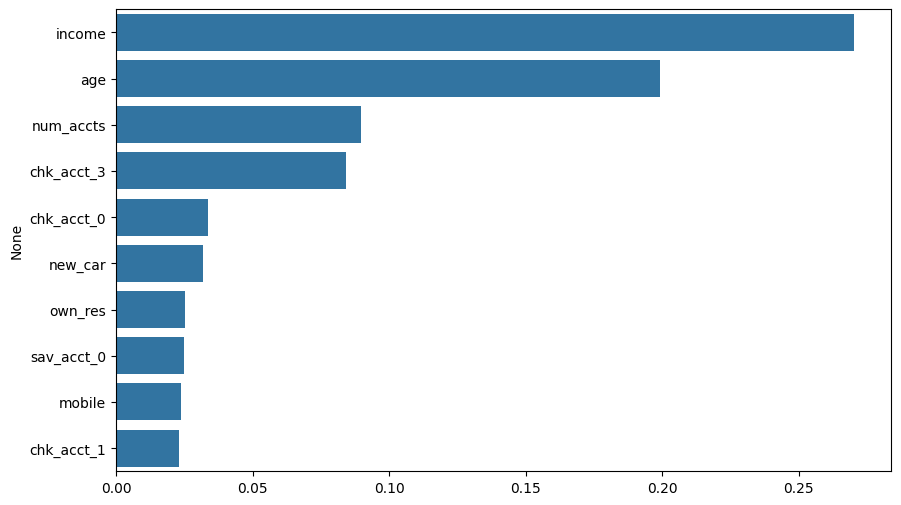

In [26]:

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))
rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=rf_importance.head(10).values,
            y=rf_importance.head(10).index)

plt.show()


### Reflection:
1. Did the random forest have higher or lower test accuracy than your tuned decision tree?
2. Which variables were most important in the random forest? Were they the same variables that appeared near the top of your decision tree?

### ✍️ Your Response: 🔧
1.
2.

### 5.5 Create a Gradient Boosting Model

Gradient boosting also combines many small trees, but it builds them in sequence. Each new tree attempts to improve the mistakes made by the earlier trees. This can create a strong predictive model, although its settings should be chosen carefully to avoid overfitting.

### Do the following:

- Import and create a GradientBoostingClassifier model.
- Start with n_estimators=100, learning_rate=0.1, max_depth=3, and random_state=42.
- Fit the model using the same training data.
- Predict whether customers in the test data will answer.
- Calculate test accuracy and display a confusion matrix.
- Create a feature-importance chart for the gradient boosting model.

Gradient Boosting Accuracy: 88.27 %
Confusion Matrix:
[[2346  328]
 [ 364 2862]]


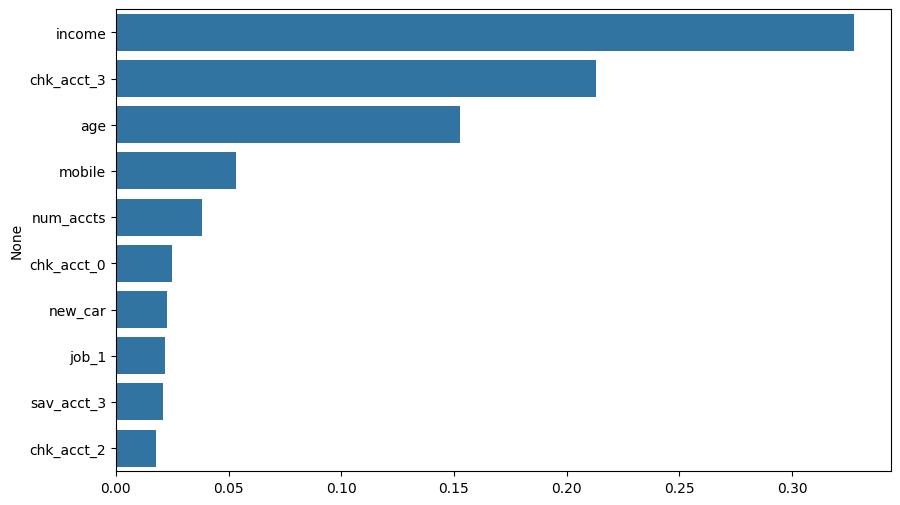

In [27]:

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)
gb_accuracy = accuracy_score(y_test, gb_pred)

print("Gradient Boosting Accuracy:", round(gb_accuracy * 100, 2), "%")
print("Confusion Matrix:")
print(confusion_matrix(y_test, gb_pred))
gb_importance = pd.Series(
    gb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=gb_importance.head(10).values,
            y=gb_importance.head(10).index)
plt.show()


### Reflection:

1. Which model had better test accuracy: the random forest or gradient boosting model?
2. In your own words, how does gradient boosting differ from a random forest?

### ✍️ Your Response: 🔧

1.  Random forest

2. Gradient does it one tree at a time while random forests does multiple


## 5.6 Compare Models Using Accuracy and Profit

Accuracy is useful, but AdviseInvest ultimately cares about staffing and profit. Compare your tuned decision tree, random forest, and gradient boosting models using both measures.

### Do the following:
- Create a table with one row for each model.
- Include each model's test accuracy, true positives, false positives, and estimated profit.
- Calculate model profit using the same business rules from Step 5:
- profit = (true positives × 75) - (false positives × 25)
- Create a bar chart comparing the test accuracy of the three models.
- Identify the model you would recommend for use on new customer data. Your choice should consider both accuracy and profit.

In [28]:
# Example structure; replace the values with your own calculations
model_results = pd.DataFrame({
    'Model': ['Tuned Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Test Accuracy': [tree_accuracy, rf_accuracy, gb_accuracy],
    'True Positives': [tree_tp, rf_tp, gb_tp],
    'False Positives': [tree_fp, rf_fp, gb_fp],
    'Estimated Profit': [tree_profit, rf_profit, gb_profit]
})

NameError: name 'tree_tp' is not defined

,Model,Test Accuracy,True Positives,False Positives,Estimated Profit
1,Random Forest,1.000000,3226,0,241950
2,Gradient Boosting,0.882712,2862,328,206450
0,Tuned Decision Tree,0.836949,2602,338,186700


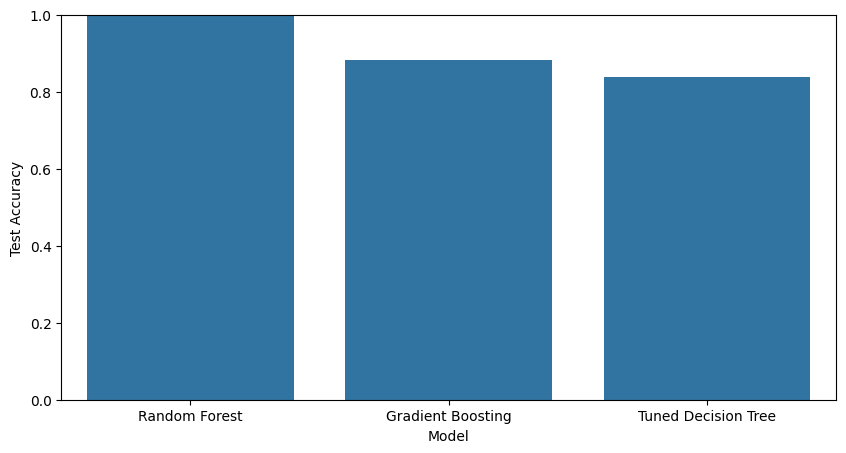

Highest  Random Forest
Estimated Profit 241950


In [29]:

def evaluate_model(name, model):
    predictions = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    return {
        'Model': name,
        'Test Accuracy': accuracy_score(y_test, predictions),
        'True Positives': tp,
        'False Positives': fp,
        'Estimated Profit': (tp * 75) - (fp * 25)
    }

model_results = pd.DataFrame([
    evaluate_model('Tuned Decision Tree', tuned_tree),
    evaluate_model('Random Forest', rf_model),
    evaluate_model('Gradient Boosting', gb_model)
])

model_results = model_results.sort_values(
    'Estimated Profit', ascending=False
)

display(model_results)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=model_results,
    x='Model',
    y='Test Accuracy'
)

plt.ylim(0, 1)
plt.show()
best_model_name = model_results.iloc[0]['Model']

print("Highest ", best_model_name)
print("Estimated Profit",
      model_results.iloc[0]['Estimated Profit'])

## 5.7 Apply the Best Model to New Customers

### Do the Following

- Import the "adviseinvest_new_customer_data.csv" file
- Copy and paste the applicable data cleanup and data-type conversion steps from 2.1 through 2.3.
- Make the new-customer variables match the columns used to train your models. If you used pd.get_dummies(), ensure that the new dataset has the same - dummy-variable columns as the training data.
- Using the model you recommended in Step 5.6, predict each customer's target variable by feeding the new customer data into the model.
- Predict the number of customers who will be yes/no for the target variable

In [31]:

new_customers = pd.read_csv(
    'adviseinvest_new_customer_data.csv'
)
customer_ids = new_customers['customer_id'].copy()

new_clean = new_customers.drop(
    columns=['customer_id', 'answered', 'product'],
    errors='ignore'
).copy()
new_clean = new_clean.drop(
    columns=['age_group'], errors='ignore'
)
for col in new_clean.columns:
    if col in df_clean.columns:
        if new_clean[col].isna().any():
            new_clean[col] = new_clean[col].fillna(
                df_clean[col].mode(dropna=True)[0]
            )
new_X = pd.get_dummies(new_clean)


new_X = new_X.reindex(
    columns=X_train.columns, fill_value=0
)

models = {
    'Tuned Decision Tree': tuned_tree,
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model
}

best_model = models[best_model_name]

new_predictions = best_model.predict(new_X)

prediction_results = pd.DataFrame({
    'Customer ID': customer_ids,
    'Predicted Answer': new_predictions
})

print("Predicted to Answer:",
      (new_predictions == 1).sum())

print("Predicted Not to Answer:",
      (new_predictions == 0).sum())

display(prediction_results.head(10))


FileNotFoundError: [Errno 2] No such file or directory: 'adviseinvest_new_customer_data.csv'

### Reflection:

1. Which model produced the highest estimated profit? Was it also the most accurate model?
2. Why might a business select a model with slightly lower accuracy?
3. Which model would be easiest to explain to the Director of Sales? Which model would you recommend using?

### ✍️ Your Response: 🔧
 1.
 2.
 3.






# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1
Yes some of the models had rpofit increasein profit.
6.2
Advise Invest could use the model by knowhich which customers are going to answer more on average which will increase profits by allowing them to get more calls answered


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"